<a href="https://colab.research.google.com/github/Madisxnki/project2-tcga-p53-capstone/blob/main/02_p53_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Notebook 02 — Does your gene respond to p53 loss?

**Produces:** a landscape, two statistical comparisons, one figure, and
the assembled answer.

---

> **This notebook does not need Notebook 01.** Its data file arrives
> already clean. If Notebook 01 defeated you, start here — you lose
> nothing.

Four functions, each with its own check:

| | question | why you ask it |
|---|---|---|
| `expression_landscape` | where is my gene expressed across cancers? | is it even switched on in my tumour type? |
| `compare_groups` | tumour vs normal? mutant vs wild-type? | the actual hypothesis test |
| `plot_comparison` | what does it look like on one axis? | the figure a paper would print |
| `run_analysis` | all of it, as one answer | wiring it together |

> ### ⚠️ Run every cell, in order, from the top
>
> Your functions only exist once you have **run** the cell that defines
> them. If you edit a function, you must re-run its cell or Python
> carries on using the old version — which is the single most confusing
> bug in notebook work.
>
> If anything stops making sense, use **Runtime → Restart and run all**
> (Colab) or **Kernel → Restart & Run All** (VS Code) and start clean.

## Run this first

> ✏️ **Before you run the cell below, add your Sussex username.**
>
> Scroll to the **bottom** of the cell — **line 66 of 77** —
> and type your Sussex username (the start of your Sussex email, the
> one you log in with) between the quotes:
>
> ```python
> STUDENT_ID = "ab123"   # <-- your Sussex username
> ```
>
> Then run the cell (**Shift + Enter**). It prints your gene and cancer
> type. Change nothing else in that cell.
>
> 💡 To see line numbers in Colab: **Tools → Settings → Editor → Show
> line numbers**.

In [1]:
# Run this first. It downloads your data and sets up the self-checks.
import hashlib
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

DATA_URL = "https://raw.githubusercontent.com/HocheggerLab/tcga-capstone-2026/main/data/"

def fetch(filename):
    """Return a local data path, downloading it in Colab if needed."""
    repo_path = Path("data") / filename
    working_path = Path(filename)

    if repo_path.exists():                   # running from the repo
        return repo_path
    if not working_path.exists():            # running in Colab
        urllib.request.urlretrieve(DATA_URL + filename, working_path)
    return working_path


def my_variant(student_id):
    """Look up your gene and cancer type from your Sussex username."""
    number = str(student_id).strip().lower()
    if not number:
        raise ValueError("Type your Sussex username into "
                         "STUDENT_ID, then run this cell again.")
    key = hashlib.pbkdf2_hmac("sha256", number.encode(), b'tcga-capstone-2026',
                              2_000_000).hex()[:16]
    lookup = json.loads(Path(fetch("variant_lookup.json")).read_text())
    if key not in lookup:
        raise ValueError(f"{number} is not on the class list. Check it "
                         "against Canvas; if it is right, email the convenor.")
    gene, cancer_type = lookup[key]
    print(f"{number}: your gene is {gene}, your cancer type is {cancer_type}")
    return gene, cancer_type


def run_checks(checks):
    """Run a dict of {description: test} and report what passed.

    Each test is a zero-argument function returning True or False. A
    test that raises is reported rather than stopping the notebook, so
    you always see the full picture.
    """
    passed = 0
    for description, test in checks.items():
        try:
            ok = bool(test())
        except Exception as exc:
            print(f"\u274c {description}")
            print(f"     raised {type(exc).__name__}: {exc}")
            continue
        print(f"{'\u2705' if ok else '\u274c'} {description}")
        passed += ok
    print()
    print(f"{passed} of {len(checks)} checks passed")
    if passed < len(checks):
        print("Keep going - fix the crosses and run this cell again.")


STUDENT_ID = "wk202"   # <-- your Sussex username, e.g. "ab123"

GENE, CANCER_TYPE = my_variant(STUDENT_ID)

MY_EXPRESSION = fetch(f"expression_{GENE}_{CANCER_TYPE}.csv")
EXAMPLE_EXPRESSION = fetch("expression_example.csv")

expr = pd.read_csv(MY_EXPRESSION)
example = pd.read_csv(EXAMPLE_EXPRESSION)

print(f"my data:        {len(expr):5d} rows - {GENE} in {CANCER_TYPE}")
print(f"worked example: {len(example):5d} rows - CDKN1A in BRCA")

wk202: your gene is CCNB1, your cancer type is LUAD
my data:         5044 rows - CCNB1 in LUAD
worked example:  4935 rows - CDKN1A in BRCA


## What is in this file

One row per sample, for one gene — yours.

| column | meaning |
|---|---|
| `sample_id`, `patient_id` | who this measurement came from |
| `cancer_type` | tumour type, as a 4-letter TCGA code |
| `group` | `tumour` or `normal` |
| `tp53_status` | `MUT` or `WT` — **already worked out for you** |
| `tp53_cn` | copy number of *TP53* (for the extension) |
| `gene_cn` | copy number of *your* gene (for the extension) |
| `log2_tpm` | **the expression measurement** |

### ⚠️ Two things you must not get wrong

**`log2_tpm` is already on a log2 scale** — it is `log2(TPM + 0.001)`.
Do **not** apply `np.log2` to it. Because it is already logged, a "fold
change" here is a **difference** of medians, not a ratio.

**`tp53_status` is blank for some tumours.** Not every patient had their
DNA sequenced. Those are *unknown*, not wild-type — treat them as
wild-type and you quietly dilute your own result. Drop them.

In [2]:
# DEMO - look before you leap
print(expr.groupby("group").size(), "\n")
print(expr[expr["group"] == "tumour"].tp53_status.value_counts(dropna=False), "\n")
print("log2_tpm range:", round(expr.log2_tpm.min(), 2), "to", round(expr.log2_tpm.max(), 2))

group
normal     288
tumour    4756
dtype: int64 

tp53_status
WT     2349
MUT    2013
NaN     394
Name: count, dtype: int64 

log2_tpm range: -9.97 to 8.36


---

## Task 2 — `expression_landscape`

**Question:** how does your gene's expression vary across cancer types?

This is context. Before testing anything you want to know whether your
gene is switched on at all in your tumour type, or whether you are about
to run statistics on noise.

**Takes** `expr` — the tidy expression table.

**Returns** a DataFrame of **tumour samples only**, one row per cancer
type:

```
cancer_type, n, median_log2tpm
```

Sorted by `median_log2tpm`, **highest first**, index reset.

In [3]:
def expression_landscape(expr):
    """Summarise the gene's expression across cancer types.

    Use tumour samples to calculate the sample count and median
    log2 expression for each cancer type, then rank the cancer types
    from the highest median expression to the lowest.
    """
    # Restrict the landscape to tumours so normal samples do not affect the cancer-type summaries.
    tumours = expr[expr["group"] == "tumour"]

    # Summarise each cancer type by its number of tumour samples and median expression.
    landscape = tumours.groupby("cancer_type").agg(
        n=("log2_tpm", "size"),
        median_log2tpm=("log2_tpm", "median"),
    )

    # Put cancer_type back into the table as a column, then rank cancers by median expression.
    landscape = landscape.reset_index()
    landscape = landscape.sort_values(
        "median_log2tpm",
        ascending=False,
    )

    # Give the ranked table a consecutive index for a clear, reproducible output.
    landscape = landscape.reset_index(drop=True)

    return landscape[["cancer_type", "n", "median_log2tpm"]]
    raise NotImplementedError("expression_landscape")

In [ ]:
# CHECK - against the worked example (CDKN1A in BRCA)
landscape_check = expression_landscape(example)

run_checks({
    "returns a DataFrame":
        lambda: isinstance(landscape_check, pd.DataFrame),
    "columns are cancer_type, n, median_log2tpm":
        lambda: list(landscape_check.columns) == ["cancer_type", "n",
                                                  "median_log2tpm"],
    "one row per cancer type (12)":
        lambda: len(landscape_check) == 12,
    "sorted highest median first":
        lambda: landscape_check["median_log2tpm"].is_monotonic_decreasing,
    "index was reset":
        lambda: list(landscape_check.index) == list(range(len(landscape_check))),
    "normals were excluded":
        lambda: landscape_check["n"].sum() == (example["group"] == "tumour").sum(),
    "top cancer type matches the worked example (PAAD)":
        lambda: landscape_check["cancer_type"].iloc[0] == "PAAD",
})

✅ returns a DataFrame
✅ columns are cancer_type, n, median_log2tpm
✅ one row per cancer type (12)
✅ sorted highest median first
✅ index was reset
✅ normals were excluded
✅ top cancer type matches the worked example (PAAD)

7 of 7 checks passed


In [4]:
landscape = expression_landscape(expr)
landscape

,cancer_type,n,median_log2tpm
0,COAD,288,6.24380
1,LUSC,498,6.03445
2,ESCA,181,5.81790
3,GBM,153,5.68740
4,BRCA,1092,5.46505
5,STAD,414,5.40755
6,LUAD,513,4.92080
7,PAAD,178,4.30420
8,LIHC,369,3.88760
9,PRAD,495,3.12940


**Interpret it.** Where does your cancer type sit — near the top,
the bottom, the middle? One or two sentences below.

*LUAD sits just above the middle of the 12 cancer types, ranking seventh for CCNB1 expression. Its median expression was 4.92080 on the log₂(TPM + 0.001) scale across 513 tumour samples; this landscape provides context, but does not test whether expression differs by TP53 status.*

---

## Task 3 — `compare_groups`

Now the actual question. You run the **same test twice**, on two
different splits:

1. **Tumour vs normal**, within your cancer type — is the gene
   dysregulated in cancer at all?
2. **TP53-mutant vs wild-type**, within the tumours — **does it respond
   to p53 loss?**

### Write one function, not two

These two comparisons do the same arithmetic on different columns.
Writing `compare_tumour_normal` and `compare_tp53` as two near-identical
functions is the commonest way to lose code-quality marks here.

```python
compare_groups(expr, group_col, group_a, group_b)
```

**Takes** `expr`, a tidy expression table already filtered to the rows
you want to compare; `group_col`, the column holding the group labels;
and `group_a` and `group_b`, the two labels to compare.

**Returns** a dict with exactly these keys:

```python
{"n_a": int, "n_b": int, "median_a": float, "median_b": float,
 "difference": float, "p_value": float, "significant": bool}
```

`difference` is `median_a - median_b`. `significant` is
`p_value < 0.05`. The test is a **two-sided Mann–Whitney U**
(`scipy.stats.mannwhitneyu`), and rows with a missing `log2_tpm` or a
missing group label are dropped.

### Why Mann–Whitney and not a t-test

Expression data is not normally distributed — it is skewed, and a few
tumours express enormously more than the rest. Mann–Whitney compares
**ranks**, so it assumes no shape and one extreme tumour cannot drag the
result. That is also why you report **medians**, not means.

In [5]:
def compare_groups(expr, group_col, group_a, group_b):
    """Compare expression between two labelled groups.

    Exclude rows missing the expression value or group label, then
    compare the groups' medians with a two-sided Mann–Whitney U test.
    The reported difference is the median in group A minus the median
    in group B.
    """
    # Exclude incomplete rows before calculating group summaries or running the test.
    comparison_data = expr[[group_col, "log2_tpm"]].dropna()

    # Select expression values for the two groups specified by the caller.
    values_a = comparison_data[
        comparison_data[group_col] == group_a
    ]["log2_tpm"]

    values_b = comparison_data[
        comparison_data[group_col] == group_b
    ]["log2_tpm"]

    # Record each group's sample size and median; the sign of the difference
    # indicates whether the median is higher in group A or group B.
    n_a = len(values_a)
    n_b = len(values_b)
    median_a = float(values_a.median())
    median_b = float(values_b.median())
    difference = median_a - median_b

    # Use a two-sided test to assess whether expression distributions differ
    # without specifying the direction in advance.
    test_result = mannwhitneyu(
        values_a,
        values_b,
        alternative="two-sided",
    )
    p_value = float(test_result.pvalue)

    # Apply the project's 0.05 significance threshold and return the
    # sample sizes, effect summary and test result together.
    return {
        "n_a": n_a,
        "n_b": n_b,
        "median_a": median_a,
        "median_b": median_b,
        "difference": difference,
        "p_value": p_value,
        "significant": p_value < 0.05,
    }
    raise NotImplementedError("compare_groups")

In [6]:
# CHECK - against the worked example (CDKN1A in BRCA)
example_brca = example[example["cancer_type"] == "BRCA"]
example_tumours = example_brca[example_brca["group"] == "tumour"]

tn_check = compare_groups(example_brca, "group", "tumour", "normal")
tp_check = compare_groups(example_tumours, "tp53_status", "MUT", "WT")

KEYS_REQUIRED = {"n_a", "n_b", "median_a", "median_b", "difference",
                  "p_value", "significant"}

run_checks({
    "returns a dict with exactly the seven keys":
        lambda: set(tn_check) == KEYS_REQUIRED,
    "difference really is median_a minus median_b":
        lambda: abs(tn_check["difference"]
                    - (tn_check["median_a"] - tn_check["median_b"])) < 1e-9,
    "significant agrees with p_value < 0.05":
        lambda: tn_check["significant"] == (tn_check["p_value"] < 0.05),
    "tumour vs normal group sizes match (1092 vs 179)":
        lambda: (tn_check["n_a"], tn_check["n_b"]) == (1092, 179),
    "tumour vs normal difference matches (-1.0967)":
        lambda: abs(tn_check["difference"] - (-1.096650)) < 1e-4,
    "TP53 group sizes match (261 mutant vs 524 wild-type)":
        lambda: (tp_check["n_a"], tp_check["n_b"]) == (261, 524),
    "TP53 difference matches (-0.6540) - p21 falls when p53 is lost":
        lambda: abs(tp_check["difference"] - (-0.654050)) < 1e-4,
})

✅ returns a dict with exactly the seven keys
✅ difference really is median_a minus median_b
✅ significant agrees with p_value < 0.05
✅ tumour vs normal group sizes match (1092 vs 179)
✅ tumour vs normal difference matches (-1.0967)
✅ TP53 group sizes match (261 mutant vs 524 wild-type)
✅ TP53 difference matches (-0.6540) - p21 falls when p53 is lost

7 of 7 checks passed


In [7]:
# comparison 1 - tumour vs normal, in your cancer type
mine = expr[expr["cancer_type"] == CANCER_TYPE]
tumour_vs_normal = compare_groups(mine, "group", "tumour", "normal")
tumour_vs_normal

{'n_a': 513,
 'n_b': 288,
 'median_a': 4.9208,
 'median_b': 1.8937499999999998,
 'difference': 3.02705,
 'p_value': 1.3170542702144197e-104,
 'significant': True}

In [8]:
# comparison 2 - TP53 mutant vs wild-type, tumours only
my_tumours = mine[mine["group"] == "tumour"]
tp53 = compare_groups(my_tumours, "tp53_status", "MUT", "WT")
tp53

{'n_a': 257,
 'n_b': 250,
 'median_a': 5.3194,
 'median_b': 4.3334,
 'difference': 0.9859999999999998,
 'p_value': 2.6150021865673586e-13,
 'significant': True}

**Interpret it.** For the TP53 comparison: which direction, how
big, and is that consistent with your gene being a p53 target, a
proliferation gene, or neither?

If your p-value is above 0.05, say so plainly and say what it means. **A
null result is a result.** Do not go hunting for a different test until
one gives you a star.

> 💡 With these group sizes a p-value can underflow and print as `0.0`.
> That means "smaller than Python can represent", not "exactly zero".
> Report it as `p < 1e-300`, never as `p = 0`.

*In LUAD, CCNB1 expression was higher in TP53-mutant than in wild-type tumours by 0.986 log₂ units (257 vs 250 samples, p = 2.62 × 10⁻¹³), a significant difference consistent with a proliferation-associated gene being less restrained when p53 function is lost, rather than with a direct p53 target being switched on by p53. CCNB1 expression was also higher in tumours than in normal tissue by 3.027 log₂ units (513 vs 288 samples, p = 1.32 × 10⁻¹⁰⁴); these observational comparisons support an association with TP53 status but do not establish that p53 loss causes the increase.*

---

## Task 4 — `plot_comparison`

**One axis, three groups:** normal tissue, TP53 wild-type tumour,
TP53-mutant tumour. Read left to right it tells the whole story — what
the gene does in healthy tissue, what cancer does to it, and what losing
p53 does on top.

```python
plot_comparison(expr, gene, cancer_type) -> matplotlib Figure
```

**Takes** `expr`, the tidy expression table; `gene`, the gene symbol
for the title; and `cancer_type`, the cancer type to plot.

**Returns** the Figure — it must `return` it, not just call
`plt.show()` — and that figure must have:

- exactly one set of axes
- three groups on the x-axis, in the order above
- a y-axis label naming the scale — it is log2(TPM + 0.001), not just
  "expression"
- a title containing your gene symbol
- the individual points visible, not only the summary — a bare box hides
  how many samples are behind it

Beyond that it is yours. Marks are for whether someone could read it
without you standing next to them.

In [9]:
def plot_comparison(expr, gene, cancer_type):
    """Plot expression in normal, TP53 wild-type and mutant samples.

    Show each group's distribution as a boxplot with its individual
    sample values overlaid, so the spread and sample-level data remain
    visible in a single figure.
    """
    # Restrict each group to the requested cancer type and exclude samples
    # without an expression measurement.
    normal = expr[
        (expr["cancer_type"] == cancer_type)
        & (expr["group"] == "normal")
    ]["log2_tpm"].dropna()

    wild_type = expr[
        (expr["cancer_type"] == cancer_type)
        & (expr["group"] == "tumour")
        & (expr["tp53_status"] == "WT")
    ]["log2_tpm"].dropna()

    mutant = expr[
        (expr["cancer_type"] == cancer_type)
        & (expr["group"] == "tumour")
        & (expr["tp53_status"] == "MUT")
    ]["log2_tpm"].dropna()

    # Keep the groups in the order needed to read the comparison:
    # normal tissue, wild-type tumours, then TP53-mutant tumours.
    groups = [normal, wild_type, mutant]
    labels = [
    f"Normal\n(n={len(normal)})",
    f"TP53 wild-type\n(n={len(wild_type)})",
    f"TP53 mutant\n(n={len(mutant)})",
    ]

    # Create one panel and size it to accommodate the three group labels.
    fig, ax = plt.subplots()
    fig.set_size_inches(8, 5)

    # Show the boxplot summaries; the individual points are added below,
    # so suppressing the fliers avoids plotting those values twice.
    ax.boxplot(groups, tick_labels=labels, showfliers=False)

    # Jitter points slightly along the x-axis so overlapping samples
    # remain visible; their expression values on the y-axis are unchanged.
    for i, values in enumerate(groups, start=1):
        x = np.random.normal(i, 0.06, len(values))
        ax.scatter(x, values, s=8, alpha=0.5)

    # State the expression scale and identify the gene and cancer type.
    ax.set_ylabel("Expression: log2(TPM + 0.001)")
    ax.set_title(f"{gene} expression in {cancer_type}")
    fig.tight_layout()

    return fig
    raise NotImplementedError("plot_comparison")

✅ returns a matplotlib Figure
✅ has exactly one set of axes
✅ has three groups on the x-axis
✅ the y-axis is labelled
✅ the y-label mentions the log2 scale
✅ the title names the gene

6 of 6 checks passed


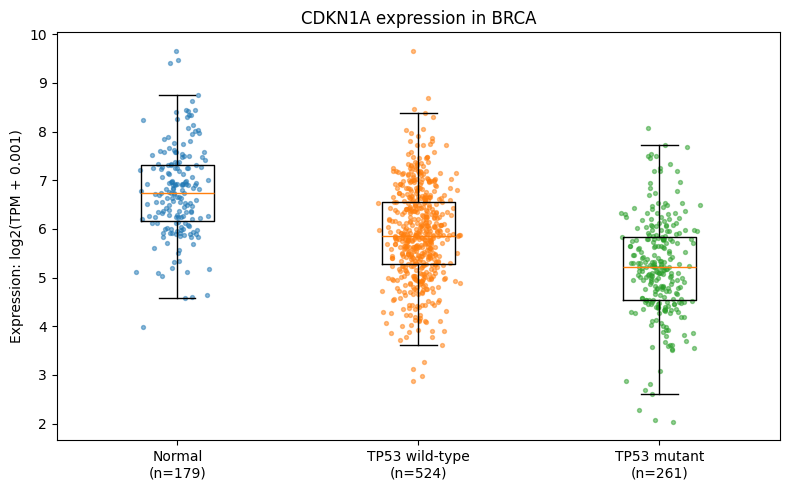

In [ ]:
# CHECK - structure only. How it *looks* is marked by eye.
fig_check = plot_comparison(example, "CDKN1A", "BRCA")

run_checks({
    "returns a matplotlib Figure":
        lambda: isinstance(fig_check, plt.Figure),
    "has exactly one set of axes":
        lambda: len(fig_check.axes) == 1,
    "has three groups on the x-axis":
        lambda: len(fig_check.axes[0].get_xticks()) == 3,
    "the y-axis is labelled":
        lambda: bool(fig_check.axes[0].get_ylabel().strip()),
    "the y-label mentions the log2 scale":
        lambda: "log2" in fig_check.axes[0].get_ylabel().lower(),
    "the title names the gene":
        lambda: "CDKN1A" in fig_check.axes[0].get_title(),
})

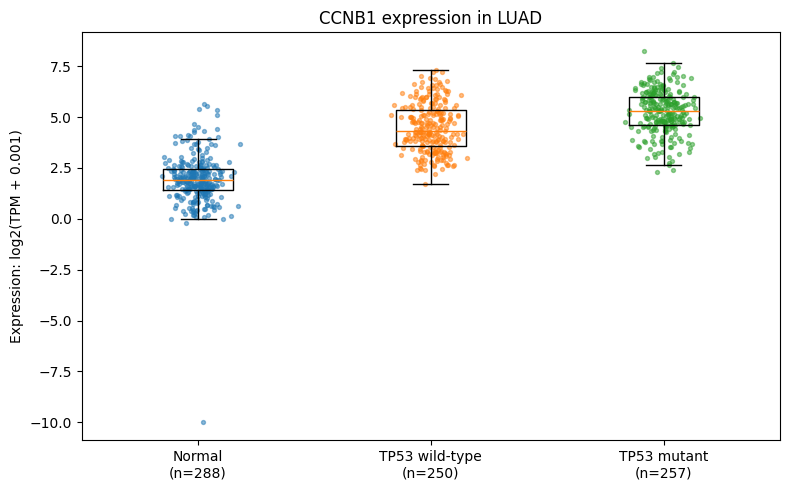

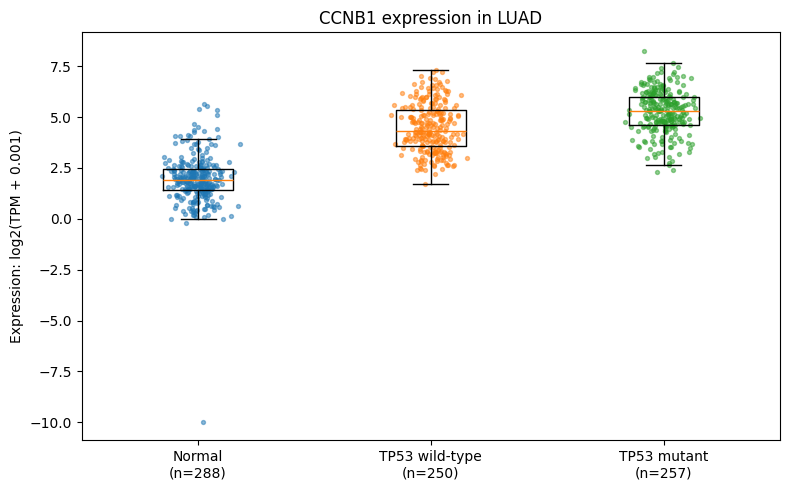

In [10]:
fig = plot_comparison(expr, GENE, CANCER_TYPE)
fig

---

## Pulling it together — `run_analysis`

One function that runs the whole analysis and returns the answer.
**Each key is marked separately**, so a key you cannot produce costs you
that key and nothing else.

```python
run_analysis(expression_path, gene, cancer_type)
```

**Takes** `expression_path`, the path to the tidy expression CSV;
`gene`; and `cancer_type`.

**Returns**:

```python
{"gene": str, "cancer_type": str, "n_samples": int,
 "landscape_top": str,          # cancer type with the highest median
 "tumour_vs_normal": {...},     # a compare_groups dict
 "tp53": {...},                 # a compare_groups dict
 "verdict": "down" | "up" | "no change"}
```

`verdict` follows from the TP53 comparison: not significant →
`"no change"`; `difference` below zero → `"down"`; above zero → `"up"`.

Note it takes **only** the expression file. Notebook 01 is not part of
this — it stands on its own, and nothing here can be blocked by it.

In [11]:
def run_analysis(expression_path, gene, cancer_type):
    """Run the expression analysis for one gene and cancer type.

    Read the tidy expression data, summarise the expression landscape,
    compare tumour with normal samples and compare TP53-mutant with
    wild-type tumours. Return the comparisons and the verdict.
    """
    # Load the tidy expression table used for both the landscape and comparisons.
    expression_data = pd.read_csv(expression_path)

    # Restrict the group comparisons to the assigned cancer type.
    cancer_data = expression_data[
        expression_data["cancer_type"] == cancer_type
    ]
    tumour_data = cancer_data[cancer_data["group"] == "tumour"]

    # Identify the cancer type with the highest median tumour expression.
    landscape = expression_landscape(expression_data)
    landscape_top = landscape["cancer_type"][0]

    # First compare tumour with normal tissue within the assigned cancer type.
    tumour_vs_normal = compare_groups(
        cancer_data,
        "group",
        "tumour",
        "normal",
    )

    # Then compare TP53-mutant with wild-type tumours in the same cancer type.
    tp53 = compare_groups(
        tumour_data,
        "tp53_status",
        "MUT",
        "WT",
    )

    # Report no change when the comparison is not significant or the
    # median difference is zero; otherwise use its sign to set the direction.
    if not tp53["significant"] or tp53["difference"] == 0:
        verdict = "no change"
    elif tp53["difference"] < 0:
        verdict = "down"
    else:
        verdict = "up"

    # Return the assigned context, landscape result and both comparisons
    # alongside the verdict derived from the TP53 comparison.
    return {
        "gene": gene,
        "cancer_type": cancer_type,
        "n_samples": len(cancer_data),
        "landscape_top": landscape_top,
        "tumour_vs_normal": tumour_vs_normal,
        "tp53": tp53,
        "verdict": verdict,
    }
    raise NotImplementedError("run_analysis")

In [12]:
# CHECK - against the worked example
result_check = run_analysis(EXAMPLE_EXPRESSION, "CDKN1A", "BRCA")

run_checks({
    "returns a dict with exactly the seven keys":
        lambda: set(result_check) == {"gene", "cancer_type", "n_samples",
                                       "landscape_top", "tumour_vs_normal",
                                       "tp53", "verdict"},
    "gene and cancer_type are passed through":
        lambda: (result_check["gene"] == "CDKN1A"
                 and result_check["cancer_type"] == "BRCA"),
    "landscape_top matches (PAAD)":
        lambda: result_check["landscape_top"] == "PAAD",
    "the nested comparisons are dicts":
        lambda: all(isinstance(result_check[k], dict)
                    for k in ("tumour_vs_normal", "tp53")),
    "verdict is one of the three allowed words":
        lambda: result_check["verdict"] in {"down", "up", "no change"},
    "verdict for CDKN1A in BRCA is 'down'":
        lambda: result_check["verdict"] == "down",
})

✅ returns a dict with exactly the seven keys
✅ gene and cancer_type are passed through
✅ landscape_top matches (PAAD)
✅ the nested comparisons are dicts
✅ verdict is one of the three allowed words
✅ verdict for CDKN1A in BRCA is 'down'

6 of 6 checks passed


In [13]:
result = run_analysis(MY_EXPRESSION, GENE, CANCER_TYPE)
result

{'gene': 'CCNB1',
 'cancer_type': 'LUAD',
 'n_samples': 801,
 'landscape_top': 'COAD',
 'tumour_vs_normal': {'n_a': 513,
  'n_b': 288,
  'median_a': 4.9208,
  'median_b': 1.8937499999999998,
  'difference': 3.02705,
  'p_value': 1.3170542702144197e-104,
  'significant': True},
 'tp53': {'n_a': 257,
  'n_b': 250,
  'median_a': 5.3194,
  'median_b': 4.3334,
  'difference': 0.9859999999999998,
  'p_value': 2.6150021865673586e-13,
  'significant': True},
 'verdict': 'up'}

---

## Your answer, in one sentence

Write it the way you would say it to another biologist. Direction, size,
p-value, and what it means.

> *In LUAD, CCNB1 expression was higher in TP53-mutant than in wild-type tumours (median difference +0.986 log₂ units, p = 2.62 × 10⁻¹³), consistent with increased CCNB1 expression being associated with loss of p53 function.*

---

## Your GitHub repository

Paste the link to your project repository below. It is marked: at
least 5 meaningful commits, and a README — see *The 15 GitHub marks* in
`00_start_here`.

**My repository:** https://github.com/Madisxnki/project2-tcga-p53-capstone